In [28]:
!pip install nibabel

In [29]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.signal as signal


In [30]:
h = nib.load('student2_2.nii')
mri = h.get_fdata()
print(mri.shape)

(256, 256, 32)


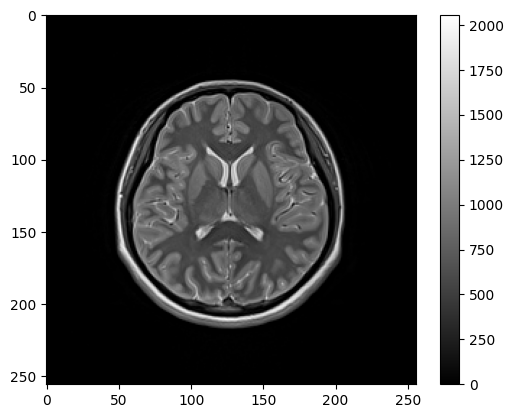

In [31]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

## Exerceise 1: Automatic Basic Global Thresholding
- 강의노트의 내용을 기반으로 하여 자동으로 global thresholding을 수행하는 영상처리코드를 작성하고, 적용한 결과를 확인하자.

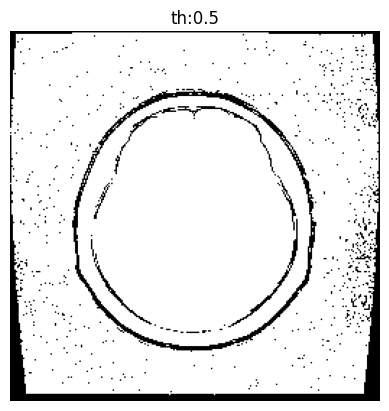

In [32]:
T_init = 1
T = []
T.append(T_init)
dT = 1000
esp = 5

## write down your algorithm
while dT>esp:
  g1 = f > T[-1]
  g2 = f <= T[-1]
  m1 = np.mean(g1)
  m2 = np.mean(g2)
  T_new = (m1 + m2)/2
  dT = abs(T_new - T[-1])
  T.append(dT)
##

bmsk = f>T[-1] # 가장 마지막 threshold로 mask를 생성
plt.imshow(bmsk,cmap='gray')
plt.axis('off')
plt.title(f'th:{T[-1]}')
plt.show()

## Exercise 2: K-means clustering
- 강의노트의 "standard" k-means clustering algorithm을 완성하여 s02.nii.gz 파일에 적용해보자.
- k=2,3,4 일 때의 결과를 s02.nii.gz에 대해 각각 비교해보자.

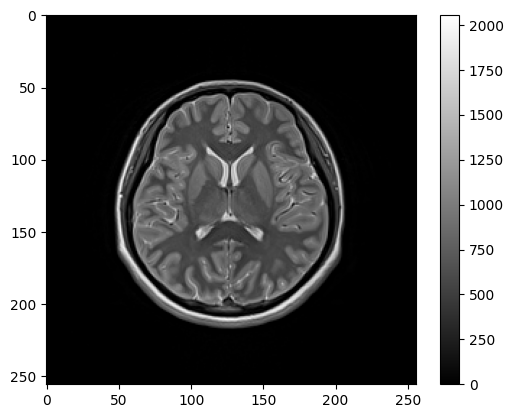

In [33]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

### k = 2 에서의 결과

In [34]:
print(f)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


[ 64. 128.]
[  5.91248043 768.93253625]
[ 13.3779618  806.97810069]
[ 14.87874927 810.79294742]


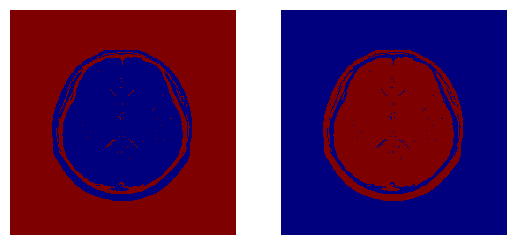

In [39]:
m_vals = np.array([64., 128.]) # 첫 array
c = np.zeros((f.shape[0],f.shape[1],len(m_vals))) # 거리 계산 맵 (256,256,2)
cmap = np.zeros_like(f) # 클래스 맵 정의 (256,256)
m_vals_new = np.zeros(m_vals.shape) #[0,0]
E=10000
eps = 1

while E>eps:
  print(m_vals)
  for i in range(len(m_vals)):
    c[:,:,i]= np.abs(f - m_vals[i]) # 거리 계산

  cmap = np.argmin(c,axis=-1) # 클래스 맵 계산

  for i in range(len(m_vals)):
    m_vals_new[i] = np.mean(f[cmap==i]) # 클래스별 평균 계산

  E = np.sum(np.abs(m_vals_new - m_vals)) # 에러 계산
  m_vals = m_vals_new.copy()


for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='jet',interpolation='nearest')
  plt.axis('off')
plt.show()

### k = 3 에서의 결과

[ 64.  96. 128.]
[  5.71429532  94.20540541 771.40291098]
[  5.40995245 247.93581878 814.48676888]
[  6.27007267 405.01211454 852.35559207]
[  7.46308873 511.23058087 938.4321368 ]
[  8.69584158 557.14568326 992.20194715]
[   9.23535482  581.41193483 1021.5755276 ]
[   9.68926739  597.86074235 1041.94674958]
[   9.93698666  609.16929711 1057.59596813]
[  10.10579428  617.92901723 1070.80398162]
[  10.27753834  625.48359994 1082.84655658]
[  10.39790496  631.92417323 1093.998312  ]
[  10.62067308  637.65032049 1103.73516918]
[  10.72303659  642.87272039 1113.92086771]
[  10.77806173  647.59468488 1123.99490608]
[  10.88195991  652.05373832 1133.6041046 ]
[  10.95876356  656.57505741 1144.20583664]
[  11.02891813  660.90026821 1155.01297531]
[  11.11352578  664.80899033 1165.13348331]
[  11.19872172  668.44071988 1174.99376826]
[  11.26299834  672.37427217 1186.55616606]
[  11.35628475  676.21607537 1198.2045068 ]
[  11.4789024   680.52404163 1211.92866726]
[  11.60978214  684.70800026 1

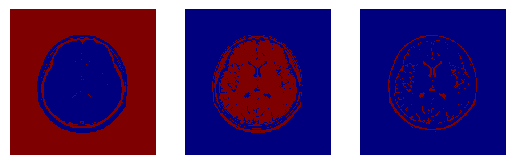

In [40]:
m_vals = np.array([64., 96., 128.]) # 첫 array
c = np.zeros((f.shape[0],f.shape[1],len(m_vals))) # 거리 계산 맵 (256,256,2)
cmap = np.zeros_like(f) # 클래스 맵 정의 (256,256)
m_vals_new = np.zeros(m_vals.shape) #[0,0]
E=10000
eps = 1

while E>eps:
  print(m_vals)
  for i in range(len(m_vals)):
    c[:,:,i]= np.abs(f - m_vals[i]) # 거리 계산

  cmap = np.argmin(c,axis=-1) # 클래스 맵 계산

  for i in range(len(m_vals)):
    m_vals_new[i] = np.mean(f[cmap==i]) # 클래스별 평균 계산

  E = np.sum(np.abs(m_vals_new - m_vals)) # 에러 계산
  m_vals = m_vals_new.copy()


for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='jet',interpolation='nearest')
  plt.axis('off')
plt.show()

### k = 4 에서의 결과

[ 32.  64.  96. 128.]
[  5.3902956   62.96414343  94.20540541 771.40291098]
[  5.14581205  49.8702011  269.21315789 814.48676888]
[  4.92304345  64.78222222 428.40500774 859.7738274 ]
[  5.14581205 113.06572069 524.69576685 948.32042001]
[  5.5023057  182.55850234 570.9725204  999.74348946]
[   5.89646996  241.18589273  599.72181639 1028.6969924 ]
[   6.2304279   286.50065189  622.35332586 1052.84084724]
[   6.56594164  328.56075808  642.44946761 1075.08341996]
[   6.86435975  367.27998176  663.24695606 1099.22225417]
[   7.15738976  406.41793152  687.35379886 1127.70168067]
[   7.48065565  447.1233616   719.14436239 1165.13348331]
[   7.88402437  488.88746439  765.86626436 1219.42440257]
[   8.38264452  518.28297127  813.46308586 1294.09925706]
[   8.81819581  535.93949244  847.63874566 1379.80640125]
[   9.00613119  546.4007034   868.61641058 1440.50775012]
[   9.15806813  553.38700214  881.47140381 1475.78376963]
[   9.22337622  557.29770318  888.87916894 1496.03848299]
[   9.271416

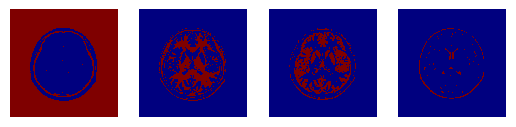

In [41]:
m_vals = np.array([32., 64., 96., 128.]) # 첫 array
c = np.zeros((f.shape[0],f.shape[1],len(m_vals))) # 거리 계산 맵 (256,256,2)
cmap = np.zeros_like(f) # 클래스 맵 정의 (256,256)
m_vals_new = np.zeros(m_vals.shape) #[0,0]
E=10000
eps = 1

while E>eps:
  print(m_vals)
  for i in range(len(m_vals)):
    c[:,:,i]= np.abs(f - m_vals[i]) # 거리 계산

  cmap = np.argmin(c,axis=-1) # 클래스 맵 계산

  for i in range(len(m_vals)):
    m_vals_new[i] = np.mean(f[cmap==i]) # 클래스별 평균 계산

  E = np.sum(np.abs(m_vals_new - m_vals)) # 에러 계산
  m_vals = m_vals_new.copy()


for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='jet',interpolation='nearest')
  plt.axis('off')
plt.show()